In [9]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
sys.path.append(base_path)


import numpy as np
import tensorflow as tf
from tqdm import tqdm

from data_loaders.data_loader_patches import DataLoaderPatches
import project_images_loader as pil
import utils.functions as fc
import utils.nifti_functions as nfc
import utils.util as util
import utils.visualization as vis
import matplotlib.pyplot as plt

from generator import MetamorphicGenerator
import discriminator as MetamorphicDiscriminator

import utils.patches_controller as patches_controller


# tf.config.set_visible_devices([], 'GPU')
# os.environ["CUDA_VISIBLE_DEVICES"]="-1"


In [10]:
input_shape = (192,224,192)

inital_lr = 1e-4

# g_optimizer = tf.keras.optimizers.Adam(inital_lr)
# d_optimizer = tf.keras.optimizers.Adam(inital_lr)

# D = MetamorphicDiscriminator()
G_h4 = MetamorphicGenerator()

checkpoint_dir = f"{current_path}/models/training_checkpoints/"
checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
checkpoint = tf.train.Checkpoint(
                                # generator_optimizer=g_optimizer,
                                # discriminator_optimizer=d_optimizer,
                                # generator=G,
                                # discriminator=D
                                G_h4 = G_h4
                                )
checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))

matching_ids = pil.get_matching_ids()

In [11]:
def save_image(id, img_gen, checkpoint_index):
    img_original, affine = pil.load_preprocessed_image(3, id)
    img_to_save = np.zeros_like(img_original)
    img_to_save[:img_gen.shape[0], :img_gen.shape[1], :img_gen.shape[2]] = img_gen
    nfc.save_nifti(img_to_save.astype(np.float32), affine, f"{current_path}/images/first_results/{id}_CHECK_{checkpoint_index}.nii.gz")


def generate_image_step(img_org, G, patch_size, patch_step, batch_size=20):
    img_patches = patches_controller.extract_patches(img_org, patch_shape=patch_size, extraction_step=patch_step).astype(np.float32)
    gen_patches = np.zeros_like(img_patches)

    for i in tqdm(range(0, len(img_patches), batch_size)):
        patches_batch = np.expand_dims(img_patches[i:min(i+batch_size, len(img_patches))], axis=-1)
        gen_result = G(patches_batch, training=False)
        gen_patches[i:min(i+batch_size, len(img_patches))] = gen_result[-1][..., 0]

    gen_image = patches_controller.perform_voting(gen_patches, 
                                                  patch_shape=patch_size, 
                                                  expected_shape=img_org.shape, 
                                                  extraction_step=patch_step,
                                                  window_sep=patch_step)
    return gen_image


def generat_image(id, G, patch_size, patch_step, backward=False):
    img_hunt3, _ = pil.load_preprocessed_image(3, id, absolute=True)
    img_hunt4, _ = pil.load_preprocessed_image(4, id, absolute=True)

    if backward:
        img_gen = generate_image_step(img_hunt4, G, patch_size=patch_size, patch_step=patch_step)
    else:
        img_gen = generate_image_step(img_hunt3, G, patch_size=patch_size, patch_step=patch_step)
   
    # vis.shows_3_images(img_hunt3, img_hunt4, img_gen_h4)
    # vis.shows_3_images(img_hunt3, img_hunt4, img_gen_h3)
    return img_hunt3, img_hunt4, img_gen


100%|██████████| 8/8 [01:02<00:00,  7.78s/it]


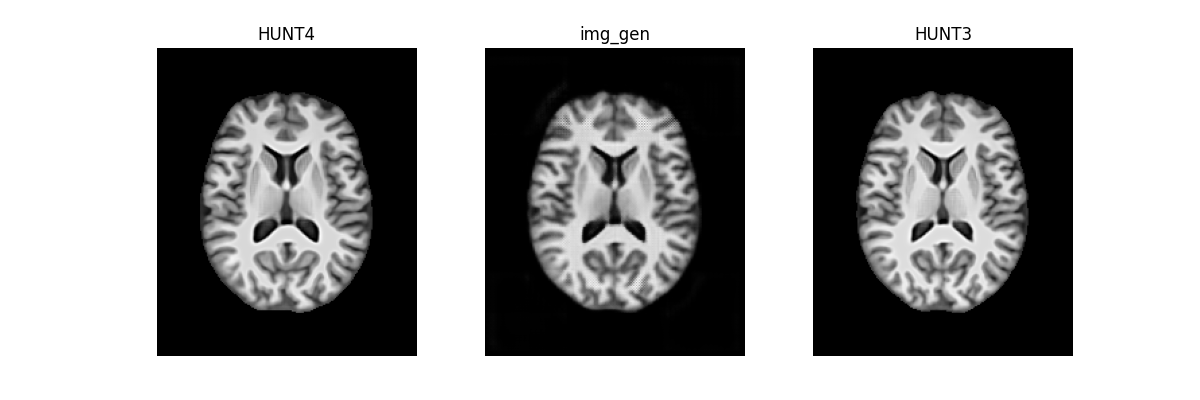

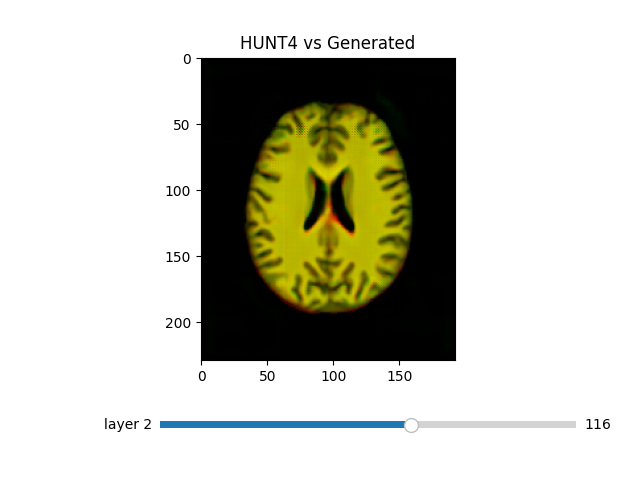

In [13]:
%matplotlib widget
# %matplotlib tk
# %matplotlib inline

current_plane = 116



# id_indexs = [301, 302, 303, 304, 305]
id_indexs = [302]
for id_index in id_indexs:
    id = matching_ids[id_index]
    img_hunt3, img_hunt4, img_gen = generat_image(id, G_h4, patch_size=(64,64,64), patch_step=(32,32,32), backward=False)

    vis.shows_3_images(img_hunt3, img_hunt4, img_gen)
    vis.show_rg_img(img_hunt4, img_gen, "HUNT4 vs Generated")

    # save image
    # id = data_train.patient_ids[id_index]
    # save_image(id, img_gen, checkpoint_index)




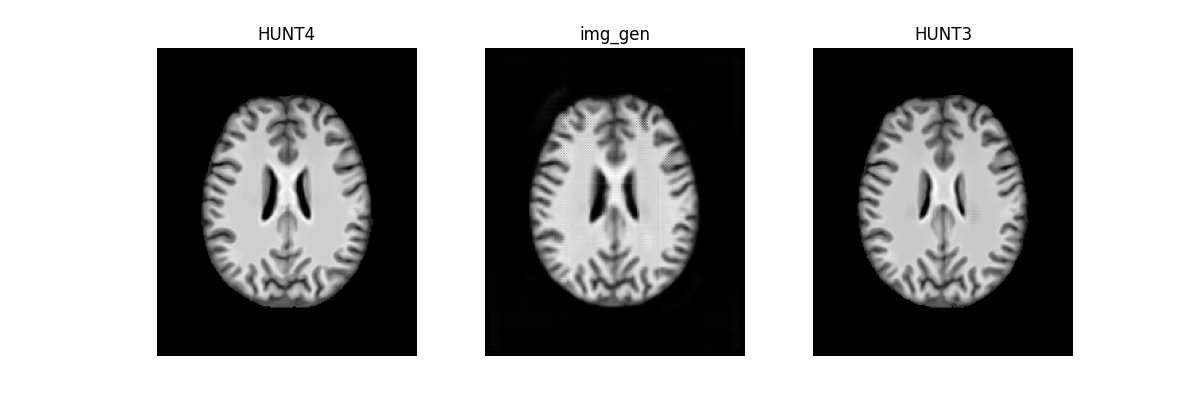

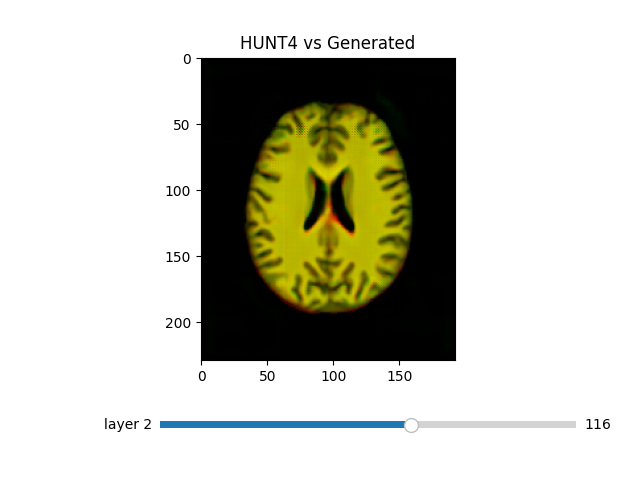

In [15]:
vis.shows_3_images(img_hunt3, img_hunt4, img_gen, current_plane=118)
vis.show_rg_img(img_hunt4, img_gen, "HUNT4 vs Generated")
